This notebook has been set up to investigate the *inster dataset names here*. 
The first step is familiarizing oneself with the data followed by the cleaning of the data.
This is in turn followed by the visualization and than the analysis can begin.

Which lifestyle  factors are associated with fertility-related outcomes, and are the magnitude, direction, and ranking of these associations similar between the artificial couples dataset and the real semen dataset?

## Set up environment

In [ ]:
# Install the required packages if not installed yet
%pip install ipykernel
%pip install pandas
%pip install numpy
%pip install scikit-learn
%pip install missingno
%pip instal seaborn

Note: you may need to restart the kernel to use updated packages.


### Load the necessary libraries

In [ ]:
import pandas as pd
import numpy as np


import seaborn as sns
import matplotlib.pyplot as plt


import missingno as msno

from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import IterativeImputer
from sklearn.ensemble import ExtraTreesRegressor, RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, LeaveOneOut, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

from urf import script_urf




## Data inspection

In [2]:
# Import the datasets
semen_df = pd.read_csv("fertility_semen_artifacts.csv")
couples_df = pd.read_csv("fertility_health_dataset_artifacts.csv")

In [3]:
# Set up a function to inspect the datasets
def inspect_datasets(dataset, name="dataset"):
    print(f"{name}:")
    print(f"Shape of {name}:", dataset.shape) # display the shape of the dataset
    print(dataset.head()) # display first 5 rows of the  dataset
    dataset.info() # display summary information about the dataset (dtype and columns, non-NA values, and memory usage)

    print(f"Missing values in {name}: in percentage")
    print(dataset.isnull().sum() * 100 / len(dataset))  # Check for missing values in the dataset per column in percentage

    print(f"Summary statistics for {name}:")
    print(dataset.describe()) # display summary statistics of the dataset (count, mean, std, min, 25%, 50%, 75%, max)
    
    print(f"Duplicate rows in {name}:")
    print(dataset.duplicated().sum()) # Check for duplicate rows in the dataset


In [4]:
# Inspect the datasets
inspect_datasets(semen_df, "Semen Dataset")
inspect_datasets(couples_df, "Couples Dataset")

Semen Dataset:
Shape of Semen Dataset: (104, 10)
   Season   Age Childish diseases Accident or serious trauma  \
0  spring  30.0                no                        yes   
1  spring  35.0               yes                         no   
2  spring  27.0               yes                         no   
3  spring  32.0                no                        yes   
4     NaN  30.0               yes                        yes   

  Surgical intervention High fevers in the last year  \
0                   yes       more than 3 months ago   
1                   yes       more than 3 months ago   
2                    no       more than 3 months ago   
3                   NaN       more than 3 months ago   
4                    no       more than 3 months ago   

  Frequency of alcohol consumption Smoking habit  \
0                      once a week    occasional   
1                      once a week         daily   
2             hardly ever or never         never   
3             hardly 

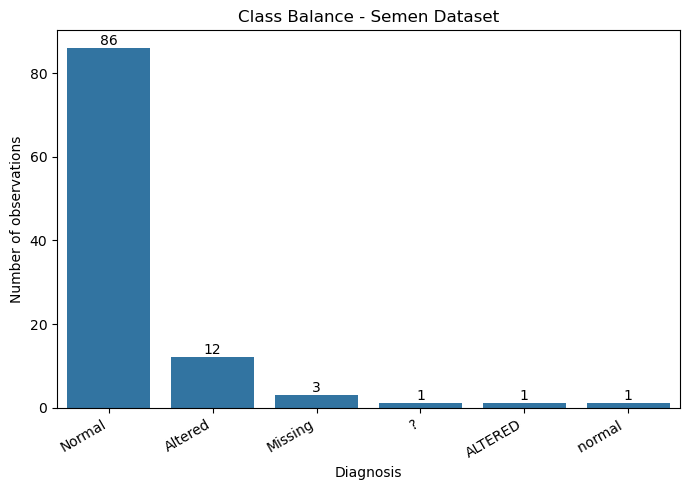

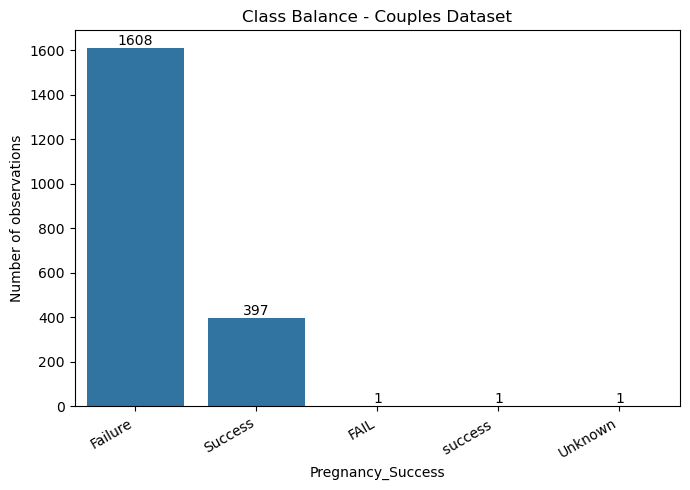

In [ ]:
# visualize raw data
def plot_class_balance(df, target_col, title):
    counts = df[target_col].fillna("Missing").astype(str).value_counts()

    plt.figure(figsize=(7, 5))
    ax = sns.barplot(
        x=counts.index,
        y=counts.values
    )

    ax.bar_label(ax.containers[0], fmt="%d")
    plt.title(title)
    plt.xlabel(target_col)
    plt.ylabel("Number of observations")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# plot class balance
plot_class_balance(
    semen_df,
    target_col="Diagnosis",
    title="Class Balance - Semen Dataset"
)

plot_class_balance(
    couples_df,
    target_col="Pregnancy_Success",
    title="Class Balance - Couples Dataset"
)

In [19]:
# drop the duplicated rows in the dataframes
semen_df = semen_df.drop_duplicates()
couples_df = couples_df.drop_duplicates()

# check if dropping of duplicated rows was succesful
print("\nSemen data shape", semen_df.shape)
print("\nCouples data shape", couples_df.shape)


Semen data shape (99, 10)

Couples data shape (2000, 19)


In [8]:
# define function checking for unique values in each column of the dataset
def check_unique_values(dataset, name="dataset"):
    print(f"Unique values in {name}:")
    unique_dict = {}
    
    # Categorical columns - show the actual values
    print("\nCategorical columns:")
    for column in dataset.select_dtypes(include=['object']).columns:
        counts = dataset[column].value_counts(dropna=False) # get the unique value count including NaN
        unique_dict[column] = counts # store the unique values in a dictionary for later use
        print(f"\n{column} ({dataset[column].nunique()} unique): {dataset[column].unique} unique")
        print(counts)

    # Numerical columns - show the number of unique values
    print("\nNumerical columns:")
    print(dataset.select_dtypes(include=["number"]).describe()) # describe instead of unique to minimize output for numerical columns as certain columns may have a large number of unique values
    return unique_dict #return the dictionary of unique values for further analysis if needed

In [9]:
# Check unique values in the datasets
semen_uniques = check_unique_values(semen_df, "Semen Dataset")  
couples_uniques = check_unique_values(couples_df, "Couples Dataset")
#see if this is needed or how to improve so that there is only 1 display of results


Unique values in Semen Dataset:

Categorical columns:

Season (8 unique): <bound method Series.unique of 0      spring
1      spring
2      spring
3      spring
4         NaN
        ...  
99     winter
100    spring
101    winter
102    winter
103    winter
Name: Season, Length: 104, dtype: str> unique
Season
spring     33
winter     30
fall       28
NaN         5
summer      4
monsoon     1
Spring      1
WINTR       1
summer?     1
Name: count, dtype: int64

Childish diseases (5 unique): <bound method Series.unique of 0       no
1      yes
2      yes
3       no
4      yes
      ... 
99      no
100    yes
101    yes
102    yes
103    yes
Name: Childish diseases, Length: 104, dtype: str> unique
Childish diseases
yes        83
no         13
NaN         5
No          1
unknown     1
YES         1
Name: count, dtype: int64

Accident or serious trauma (5 unique): <bound method Series.unique of 0      yes
1       no
2       no
3      yes
4      yes
      ... 
99     yes
100     no
101    Na

C:\Users\fille\AppData\Local\Temp\ipykernel_21760\1198179535.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in dataset.select_dtypes(include=['object']).columns:
C:\Users\fille\AppData\Local\Temp\ipykernel_21760\1198179535.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/u

In [10]:
# display the unique values in the datasets
print("\nUnique values in Semen Dataset:")
print(semen_uniques)
print(semen_df.value_counts())

print("\nUnique values in Couples Dataset:")
print(couples_uniques)
print(couples_df.value_counts())


Unique values in Semen Dataset:
{'Season': Season
spring     33
winter     30
fall       28
NaN         5
summer      4
monsoon     1
Spring      1
WINTR       1
summer?     1
Name: count, dtype: int64, 'Childish diseases': Childish diseases
yes        83
no         13
NaN         5
No          1
unknown     1
YES         1
Name: count, dtype: int64, 'Accident or serious trauma': Accident or serious trauma
no      54
yes     41
NaN      6
?        1
NO       1
yes      1
Name: count, dtype: int64, 'Surgical intervention': Surgical intervention
yes        47
no         47
NaN         6
N           2
Unknown     1
Y           1
Name: count, dtype: int64, 'High fevers in the last year': High fevers in the last year
more than 3 months ago    60
no                        27
less than 3 months ago     8
NaN                        6
< 3 mo                     1
never?                     1
more than 3 months AGO     1
Name: count, dtype: int64, 'Frequency of alcohol consumption': Frequency o

## Data clean-up

### Whitespace and casing clean up


In [11]:
# define generic placeholders to be replaced with NaN
universal_placeholders = ["unknown", "?", "Unknown", "nan", " ", "none"] # define the common placeholders to be replaced with NaN


In [12]:
# define a function to clean the datasets on column level
def clean_datasets(dataset, name="dataset"):
    cleaned_dict = {}

    for col in dataset.select_dtypes(include='object').columns: # loop through the categorical columns
        dataset[col] = (
            dataset[col]
            .str.lower() # convert to lowercase
            .str.strip() # remove whitespace
            .replace(universal_placeholders, np.nan) # replace the common placeholders with NaN
            )
        cleaned_dict[col] = dataset[col].unique() # check unique values after cleaning
    return cleaned_dict

In [13]:
# clean the datasets on column level
semen_cleaned_uniques = clean_datasets(semen_df)
couples_cleaned_uniques = clean_datasets(couples_df)

# print the cleanedAttributeError: 'numpy.ndarray' object has no attribute 'replace values in the datasets to verify the cleaning process
print("\nCleaned unique values in Semen Dataset:") 
print(semen_cleaned_uniques)
print("\nCleaned unique values in Couples Dataset:")
print(couples_cleaned_uniques)


Cleaned unique values in Semen Dataset:
{'Season': <ArrowStringArray>
['spring', nan, 'fall', 'monsoon', 'winter', 'summer', 'wintr', 'summer?']
Length: 8, dtype: str, 'Childish diseases': <ArrowStringArray>
['no', 'yes', nan]
Length: 3, dtype: str, 'Accident or serious trauma': <ArrowStringArray>
['yes', 'no', nan]
Length: 3, dtype: str, 'Surgical intervention': <ArrowStringArray>
['yes', 'no', nan, 'y', 'n']
Length: 5, dtype: str, 'High fevers in the last year': <ArrowStringArray>
['more than 3 months ago', 'less than 3 months ago',                      nan,
                 '< 3 mo',                     'no',                 'never?']
Length: 6, dtype: str, 'Frequency of alcohol consumption': <ArrowStringArray>
[         'once a week', 'hardly ever or never', 'several times a week',
          'hardly ever',  'several times a day',         'weekend only',
                    nan,            'every day',               'dailyy']
Length: 9, dtype: str, 'Smoking habit': <ArrowStringArra

C:\Users\fille\AppData\Local\Temp\ipykernel_21760\2410330588.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in dataset.select_dtypes(include='object').columns: # loop through the categorical columns
C:\Users\fille\AppData\Local\Temp\ipykernel_21760\2410330588.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
Se

### Typo and variant mapping

In [14]:
# defining the mapping for the datasets based on the suggested mappings and manual inspection of the unique values
semen_mapping = {
    "Season": {
        "summer?": "summer", 
        "wintr": "winter",
    },
    "Surgical intervention" :{
        "y": "yes",
        "n": "no"
    },
    "High fevers in the last year": {
        "never?": "no",
        "< 3 mo": "less than 3 months ago"
    },
    "Frequency of alcohol consumption": {
    "hardly ever or never": "none",
    "hardly ever": "none",
    "weekend only": "low",
    "once a week": "low",
    "several times a week": "moderate",
    "every day": "high",
    "dailyy": "high",
    "several times a day": "high"   
    },
    "Smoking habit": {
        "occassional": "yes",
        "never":"no",
        "daily": "yes",
        "heavy": "yes",
        "occasional": "yes"
        }
}

couples_mapping = {
    "PCOS": {
        'yess': 'yes'},
    "Period_Regularity": {
        "regulr": "regular"},
    "Female_Alcohol": {
        "modrate": "moderate", 
        "no_alcohol": "none"},
    "Male_Alcohol": {
        "moderatee": "moderate",
        "no_alcohol": "none", 
        "no alcohol": "none"},
    "Female_Exercise": {
        "activee": "active", 
        "no_exercise": "none"},
    "Male_Exercise": {
        "actve": "active", 
        "no_exercise": "none",
        "no exercise": "none"},
    "Pregnancy_Success": {
        "failure": "altered",
        "fail": "altered",
        "success": "normal"
    }
}

In [16]:
# Implement the mapping to the data sets
for col, mapping in semen_mapping.items():
    semen_df[col] = semen_df[col].replace(mapping)
for col, mapping in couples_mapping.items():    
    couples_df[col] = couples_df[col].astype("object").replace(mapping).astype("string")

In [17]:
# display the unique values in the datasets after mapping to verify the mapping process
print("\nUnique values in Semen Dataset after mapping:") # print header to show which dataset is shown
for col in semen_df.columns: # loop over every column
    print(col, "->", semen_df[col].unique()) # print unique values 

print("\nUnique values in Couples Dataset after mapping:")  #print header to show which dataset is shown
for col in couples_df.columns: # loop over every column
    print(col, "->", couples_df[col].unique()) # print unique values 


Unique values in Semen Dataset after mapping:
Season -> <ArrowStringArray>
['spring', nan, 'fall', 'monsoon', 'winter', 'summer']
Length: 6, dtype: str
Age -> [ 30.  35.  27.  32.  36.  29.  33.  28.  nan  31.   7.  -5. 150.  34.
  99.]
Childish diseases -> <ArrowStringArray>
['no', 'yes', nan]
Length: 3, dtype: str
Accident or serious trauma -> <ArrowStringArray>
['yes', 'no', nan]
Length: 3, dtype: str
Surgical intervention -> <ArrowStringArray>
['yes', 'no', nan]
Length: 3, dtype: str
High fevers in the last year -> <ArrowStringArray>
['more than 3 months ago', 'less than 3 months ago', nan, 'no']
Length: 4, dtype: str
Frequency of alcohol consumption -> <ArrowStringArray>
['low', 'none', 'moderate', 'high', nan]
Length: 5, dtype: str
Smoking habit -> <ArrowStringArray>
['yes', 'no', nan]
Length: 3, dtype: str
Number of hours spent sitting per day -> [ 1.60e+01  6.00e+00  9.00e+00  7.00e+00  8.00e+00       nan  5.00e+00
  2.00e+00  1.10e+01  3.00e+00 -4.00e+00  3.42e+02  1.40e+01  

In [20]:
# Drop row containing monsoon
semen_df = semen_df[semen_df.Season != "monsoon"]
print(semen_df.shape)

(99, 10)


### cleaning numerical data

In [21]:
# replace improbable values with NaN
# define bounds
semen_bounds = {
    "Age": (16, 65), # lowest and highest age found in literature
    "Number of hours spent sitting per day": (0, 24), # number of hours in a day
}
couples_bounds = {
    "Male_Age": (16, 65), # lowest and highest age found in literature
    "Female_Age": (16,65), # lowest and highest age found in literature
    "Female_BMI":(16, 40), # range from moderate thinness to extreme obesity
    "Male_BMI":(17, 40),  # range from moderate thinness to extreme obesity
    "Sperm_Count_M_per_mL": (0, 300), # Who reference values rarely exceeds this value
    "Sperm_Motility_Pct": (0, 100), # it is percentage 
    "Stress_Level": (0, 10), # normalized in the data to 10
    "Sleep_Quality": (0, 10), # normalized in the data to 10
    "Past_Pregnancies": (0, 15) # generous upper bound rarely occurs
}

# replace out of bound value with NaN instead of deleting row
for col, (low, high) in semen_bounds.items(): # loop through the dictionary
    invalid = ~semen_df[col].between(low, high) & semen_df[col].notna() # checks which values don't fall between the assigned values and names them invalid
    print(f"{col}: {invalid.sum()} implausible values")
    semen_df.loc[invalid, col] = np.nan # convert to NaN rather than dropping the row entirely 

for col, (low, high) in couples_bounds.items(): # loop through the dictionary
    invalid = ~couples_df[col].between(low, high) & couples_df[col].notna() # checks which values don't fall between the assigned values and names them invalid
    print(f"{col}: {invalid.sum()} implausible values")
    couples_df.loc[invalid, col] = np.nan # convert to NaN rather than dropping the row entirely 

Age: 4 implausible values
Number of hours spent sitting per day: 3 implausible values
Male_Age: 3 implausible values
Female_Age: 3 implausible values
Female_BMI: 3 implausible values
Male_BMI: 3 implausible values
Sperm_Count_M_per_mL: 3 implausible values
Sperm_Motility_Pct: 3 implausible values
Stress_Level: 3 implausible values
Sleep_Quality: 3 implausible values
Past_Pregnancies: 2 implausible values


### Outlier detection

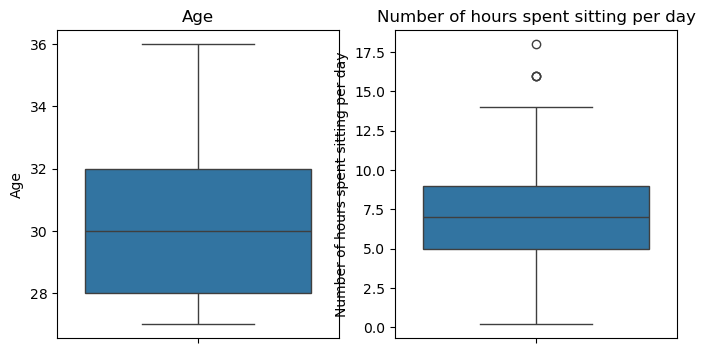

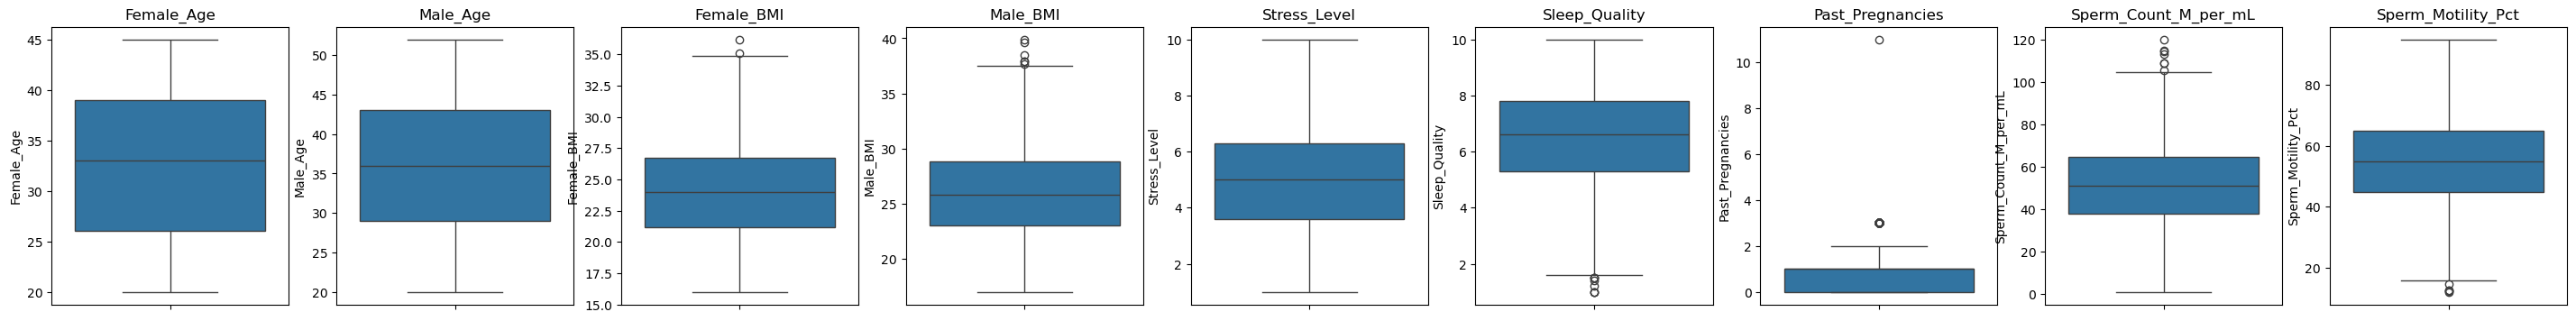

In [22]:
# define numeric_col variable
semen_numeric_cols = semen_df.select_dtypes(include = "number").columns.tolist()
couples_numeric_cols = couples_df.select_dtypes(include = "number").columns.tolist()

# visualize potential outliers using boxplots
fig, axes = plt.subplots(1, len(semen_numeric_cols), figsize=(4*len(semen_numeric_cols), 4))
for ax, col in zip(axes, semen_numeric_cols):
    sns.boxplot(y=semen_df[col], ax=ax)
    ax.set_title(col)

fig, axes = plt.subplots(1, len(couples_numeric_cols), figsize=(4*len(couples_numeric_cols), 4))
for ax, col in zip(axes, couples_numeric_cols):
    sns.boxplot(y=couples_df[col], ax=ax,)
    ax.set_title(col)

# see if you want to keep this only if you have enough time to look at it

In [57]:
def detect_outliers_iqr_summary(dataset, features):
    outliers_summary = {}

    for feature in features:
        data = dataset[feature]
        Q1 = data.quantile(0.25)
        Q3 = data.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = data[(data<lower_bound)|(data>upper_bound)]
        outliers_summary[feature] = len(outliers)
    return outliers_summary

In [24]:
semen_outliers = detect_outliers_iqr_summary(semen_df, semen_numeric_cols)
couples_outliers = detect_outliers_iqr_summary(couples_df, couples_numeric_cols)

print(semen_outliers)
print(couples_outliers)


{'Age': 0, 'Number of hours spent sitting per day': 4}
{'Female_Age': 0, 'Male_Age': 0, 'Female_BMI': 2, 'Male_BMI': 6, 'Stress_Level': 0, 'Sleep_Quality': 8, 'Past_Pregnancies': 114, 'Sperm_Count_M_per_mL': 7, 'Sperm_Motility_Pct': 5}


### Missing percentage summary

In [25]:
# drop rows with NaN in target column (diagnosis or pregnancy success)
semen_df = semen_df.dropna(subset=["Diagnosis"])
couples_df = couples_df.dropna(subset=["Pregnancy_Success"])

# print shape of dataframes
print("\nSemen data shape", semen_df.shape)
print("\nCouples data shape", couples_df.shape)



Semen data shape (95, 10)

Couples data shape (1999, 19)


In [26]:
# set up formula to obtain table with missing values for both data sets
def missing_summary (df, name="dataset"): # set up function
    missing_count = df.isnull().sum() # find the missing values and count them
    missing_pct = (missing_count / len(df)) *100 # get the percentage of missing values per column
    summary = pd.DataFrame({
        "Missing Count": missing_count,
        "Missing %": missing_pct.round(2) 
                            }) # create the summary table
    summary = summary.sort_values("Missing %", ascending=False) # sort the dataframe
    print(f"\nMissing values in {name}:")
    print(summary)
    return summary

In [27]:
# get table with the percentage of missing values
semen_missing = missing_summary(semen_df, "Semen Dataset")
couples_missing = missing_summary(couples_df, "Couples Dataset")


Missing values in Semen Dataset:
                                       Missing Count  Missing %
Age                                                9       9.47
Number of hours spent sitting per day              8       8.42
Surgical intervention                              6       6.32
Childish diseases                                  6       6.32
Accident or serious trauma                         6       6.32
Season                                             5       5.26
High fevers in the last year                       5       5.26
Frequency of alcohol consumption                   5       5.26
Smoking habit                                      5       5.26
Diagnosis                                          0       0.00

Missing values in Couples Dataset:
                      Missing Count  Missing %
Female_Age                       53       2.65
Male_Age                         53       2.65
Female_BMI                       53       2.65
Sperm_Count_M_per_mL             53   

### investigate whether there is a correlation in the missing data

Text(0.5, 1.0, 'Missingness correlation matrix for Couples dataframe')

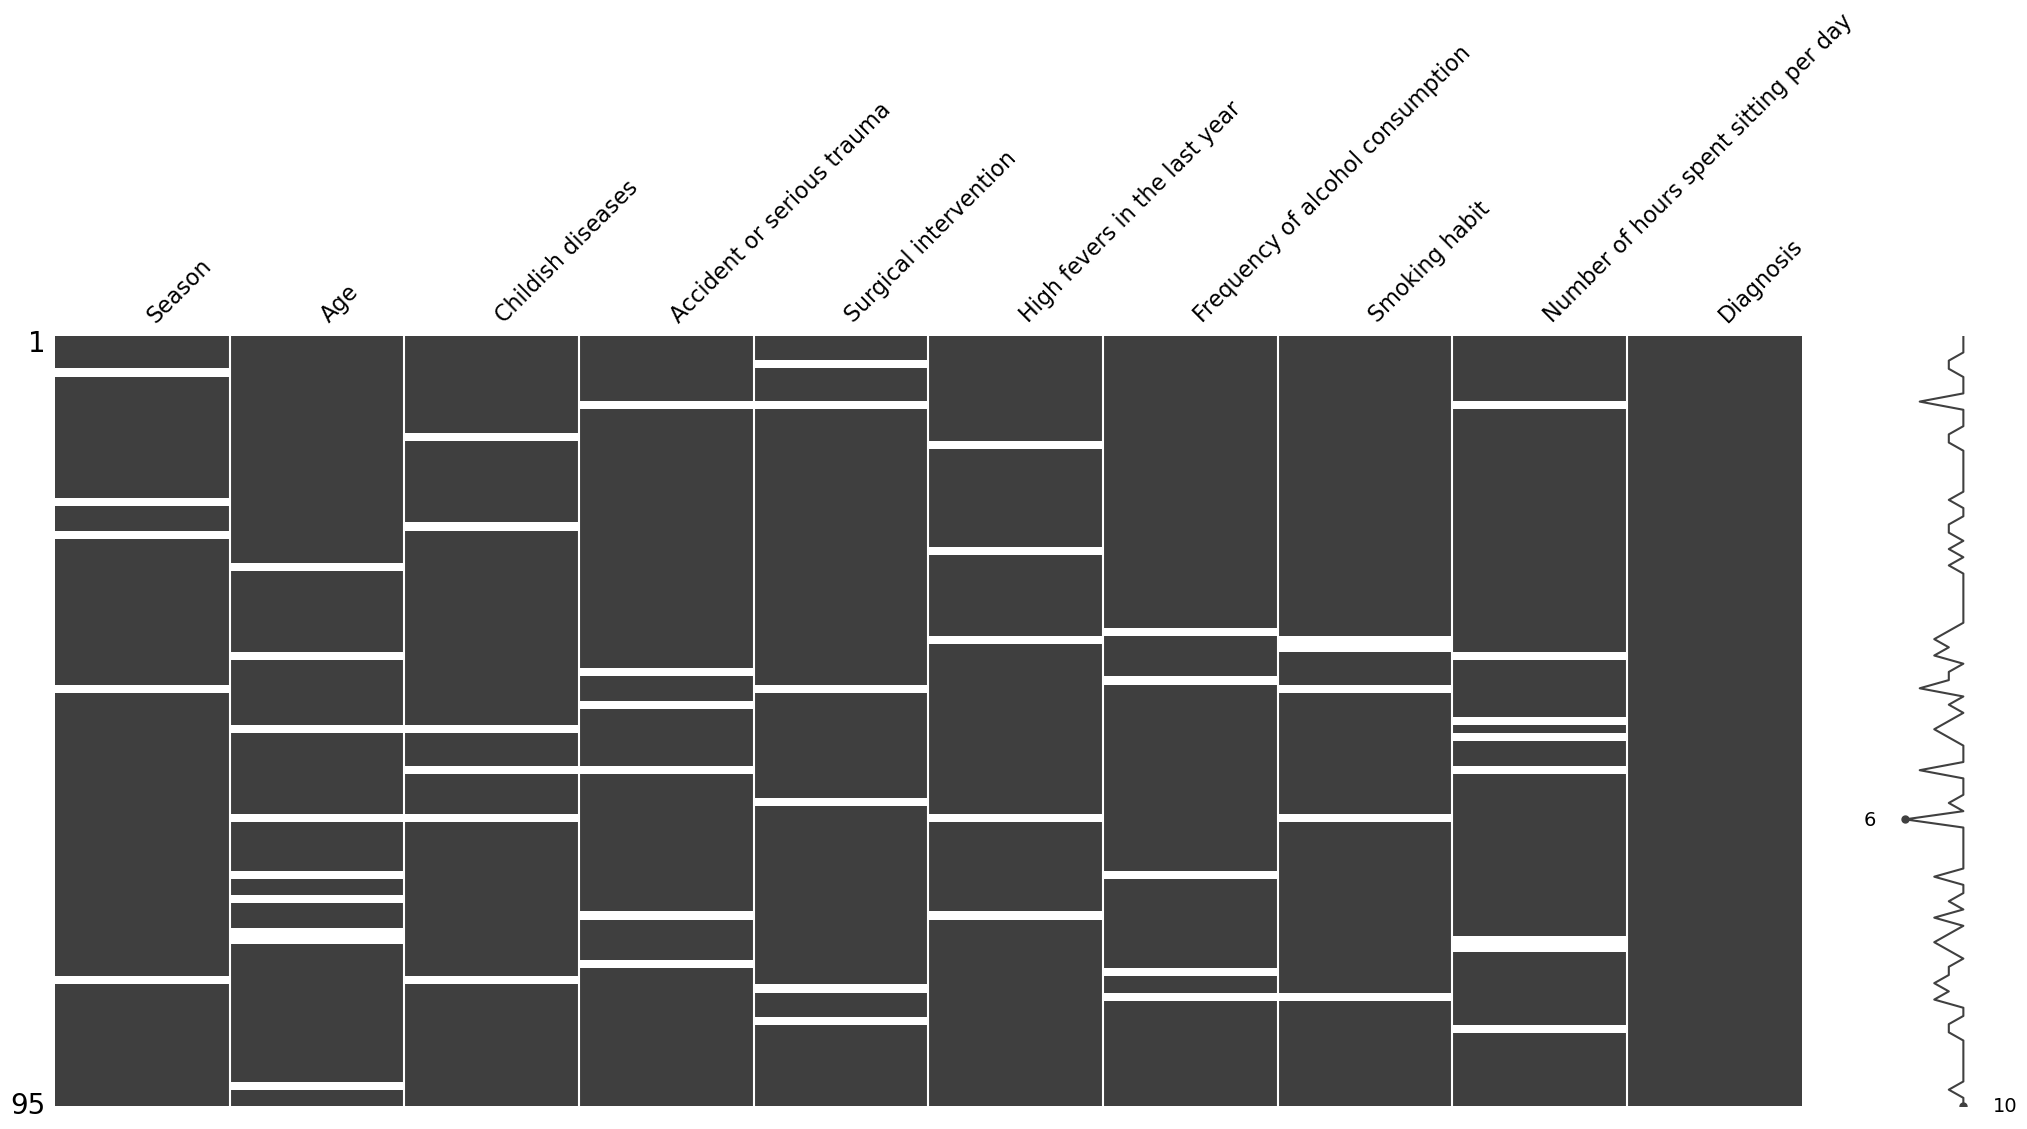

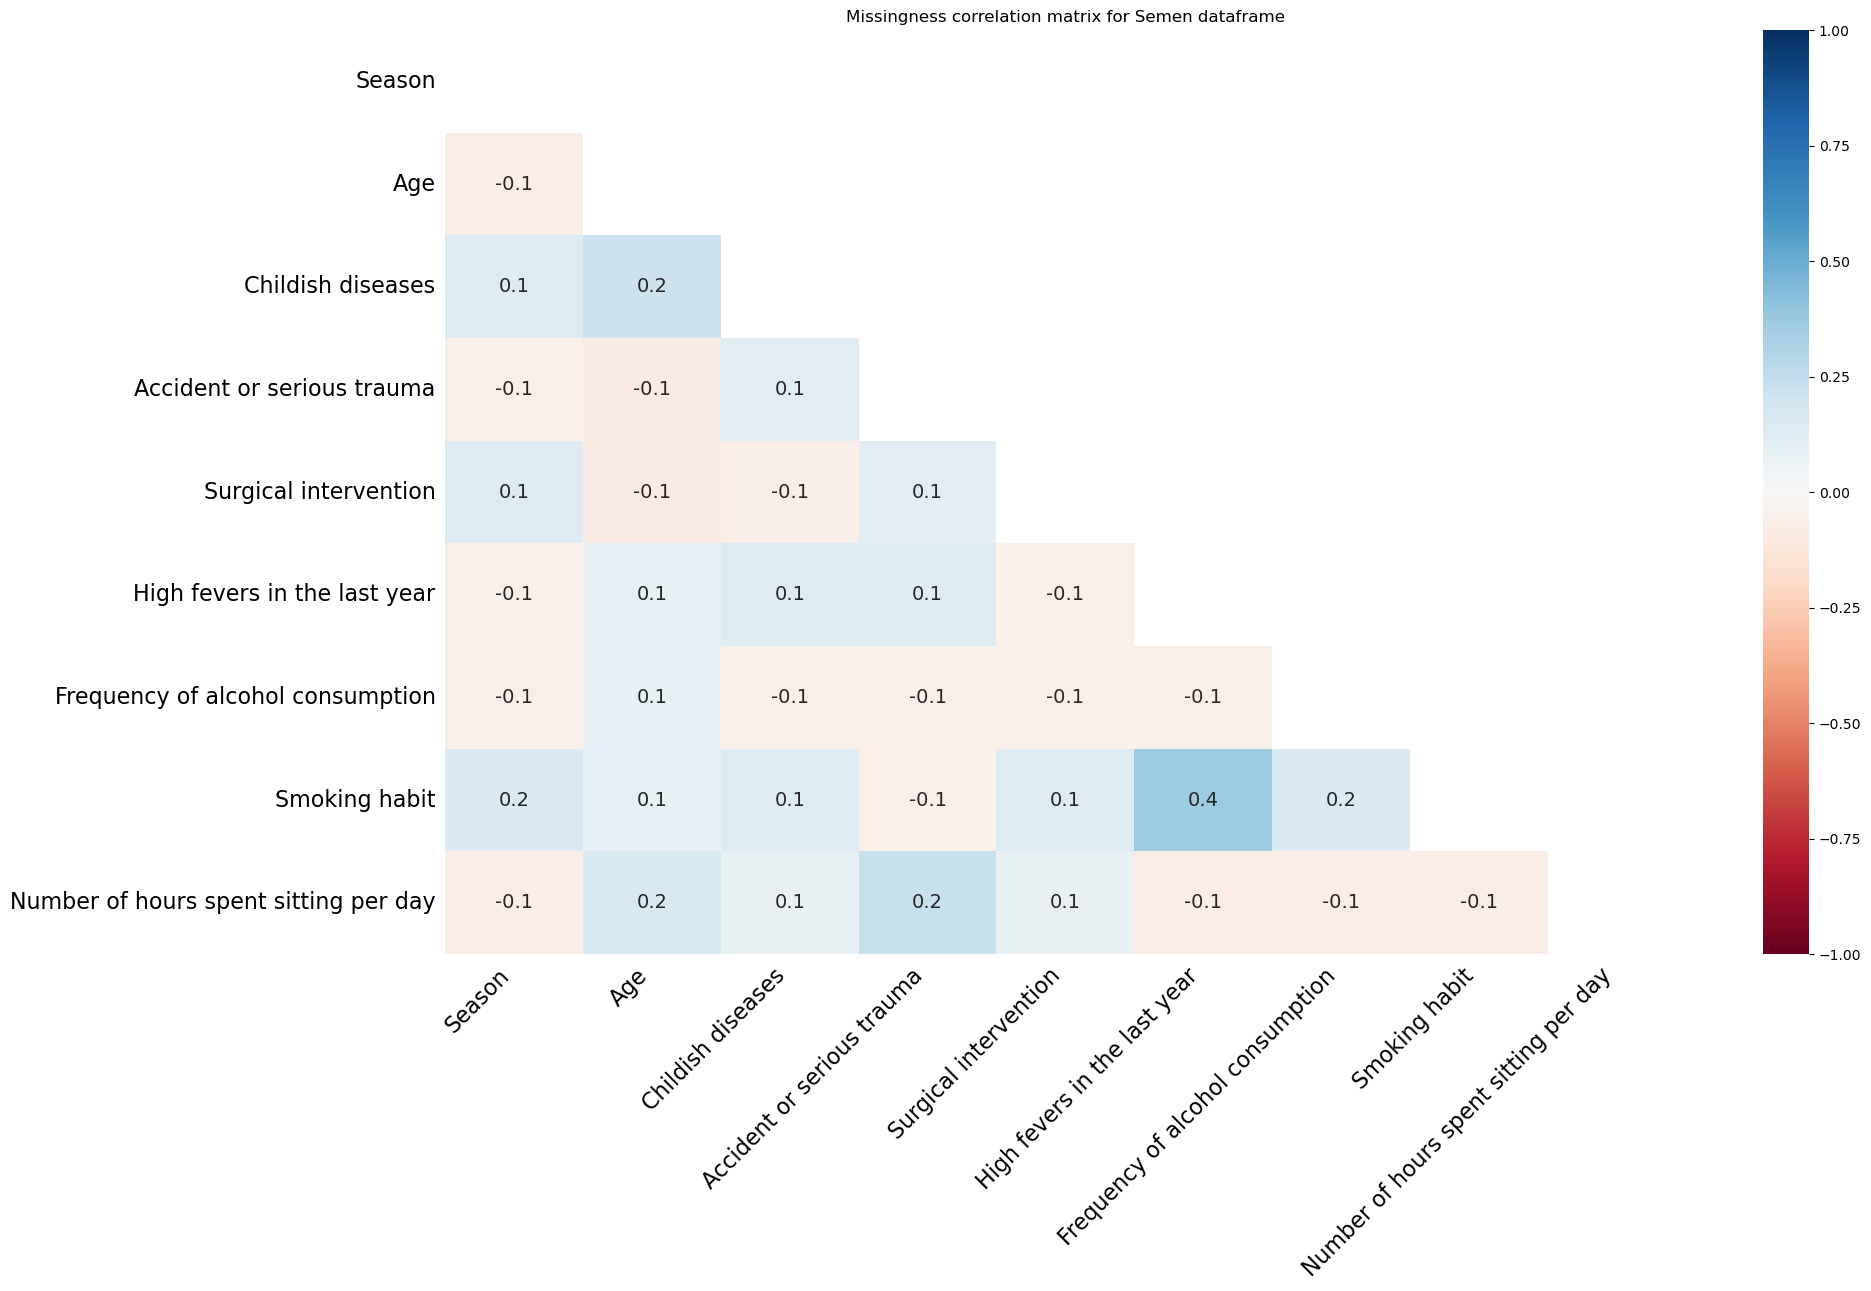

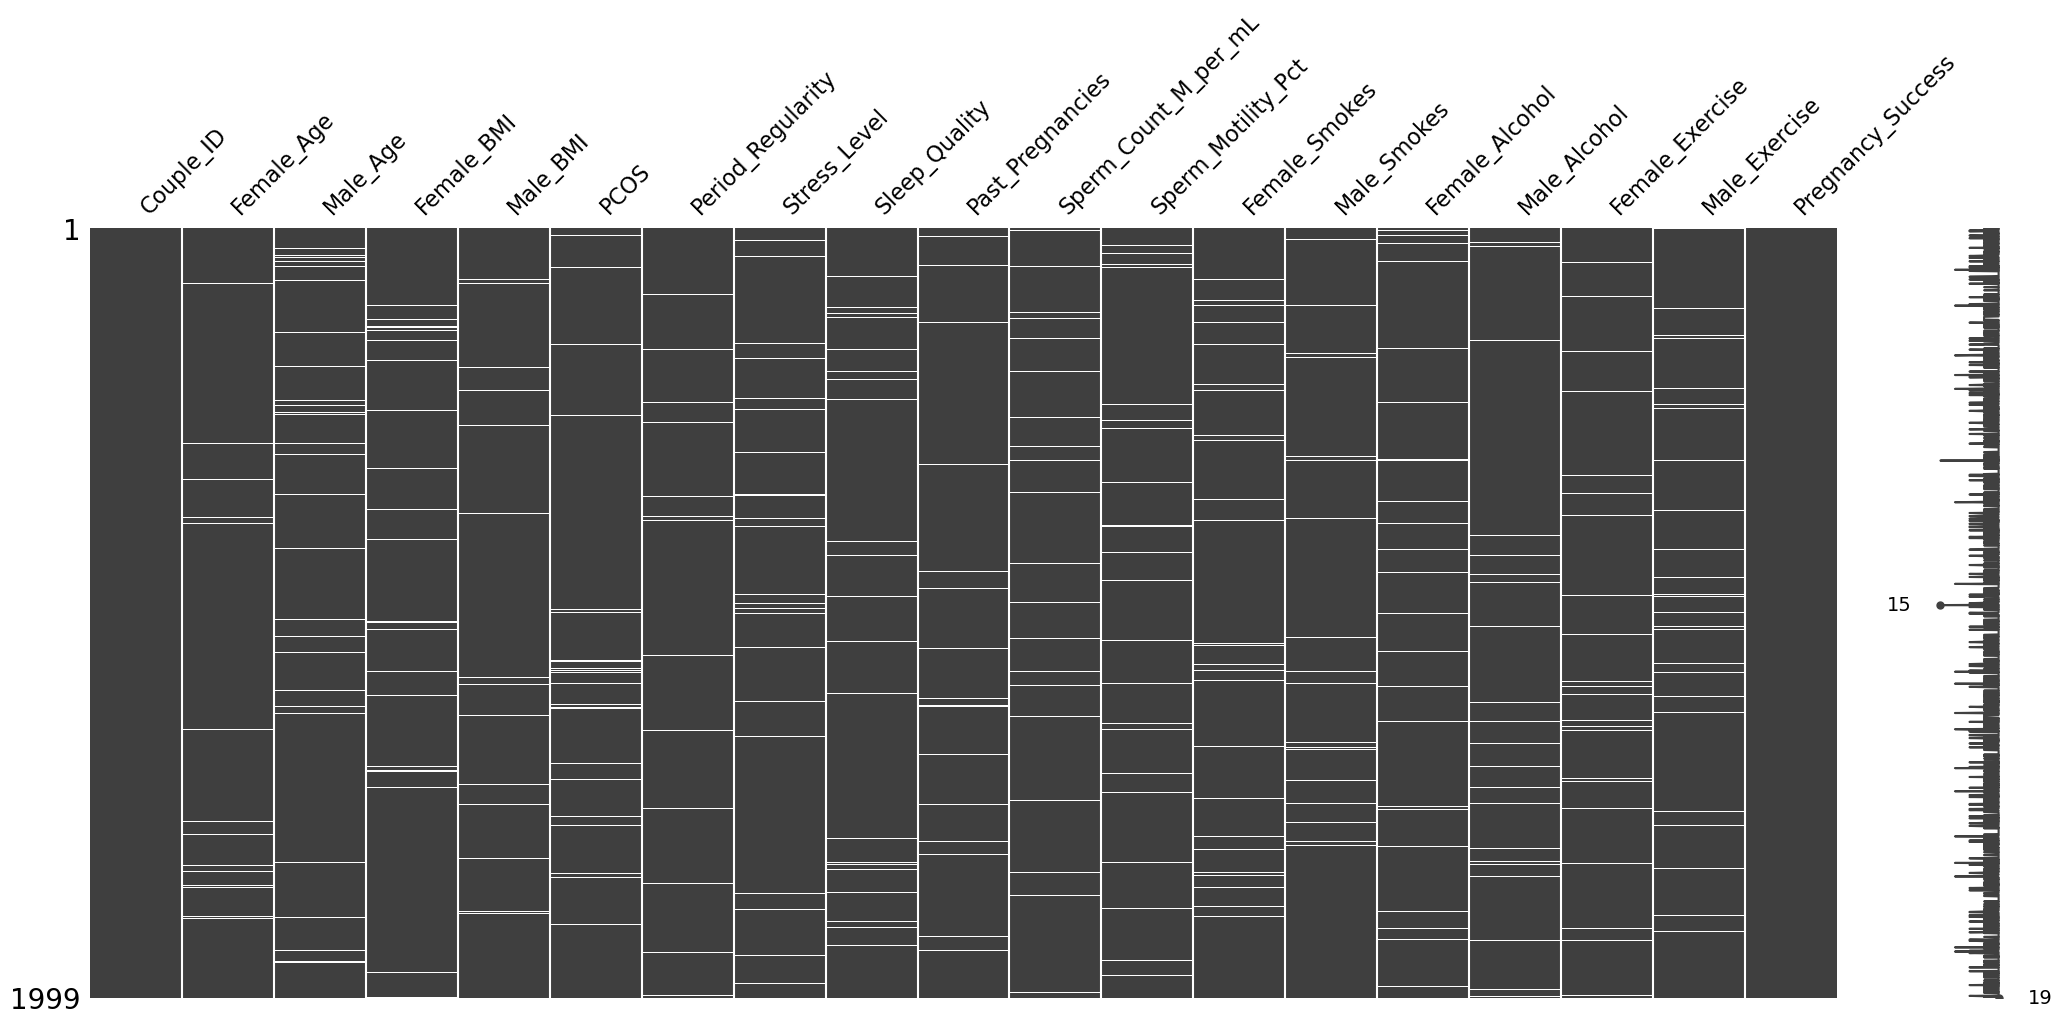

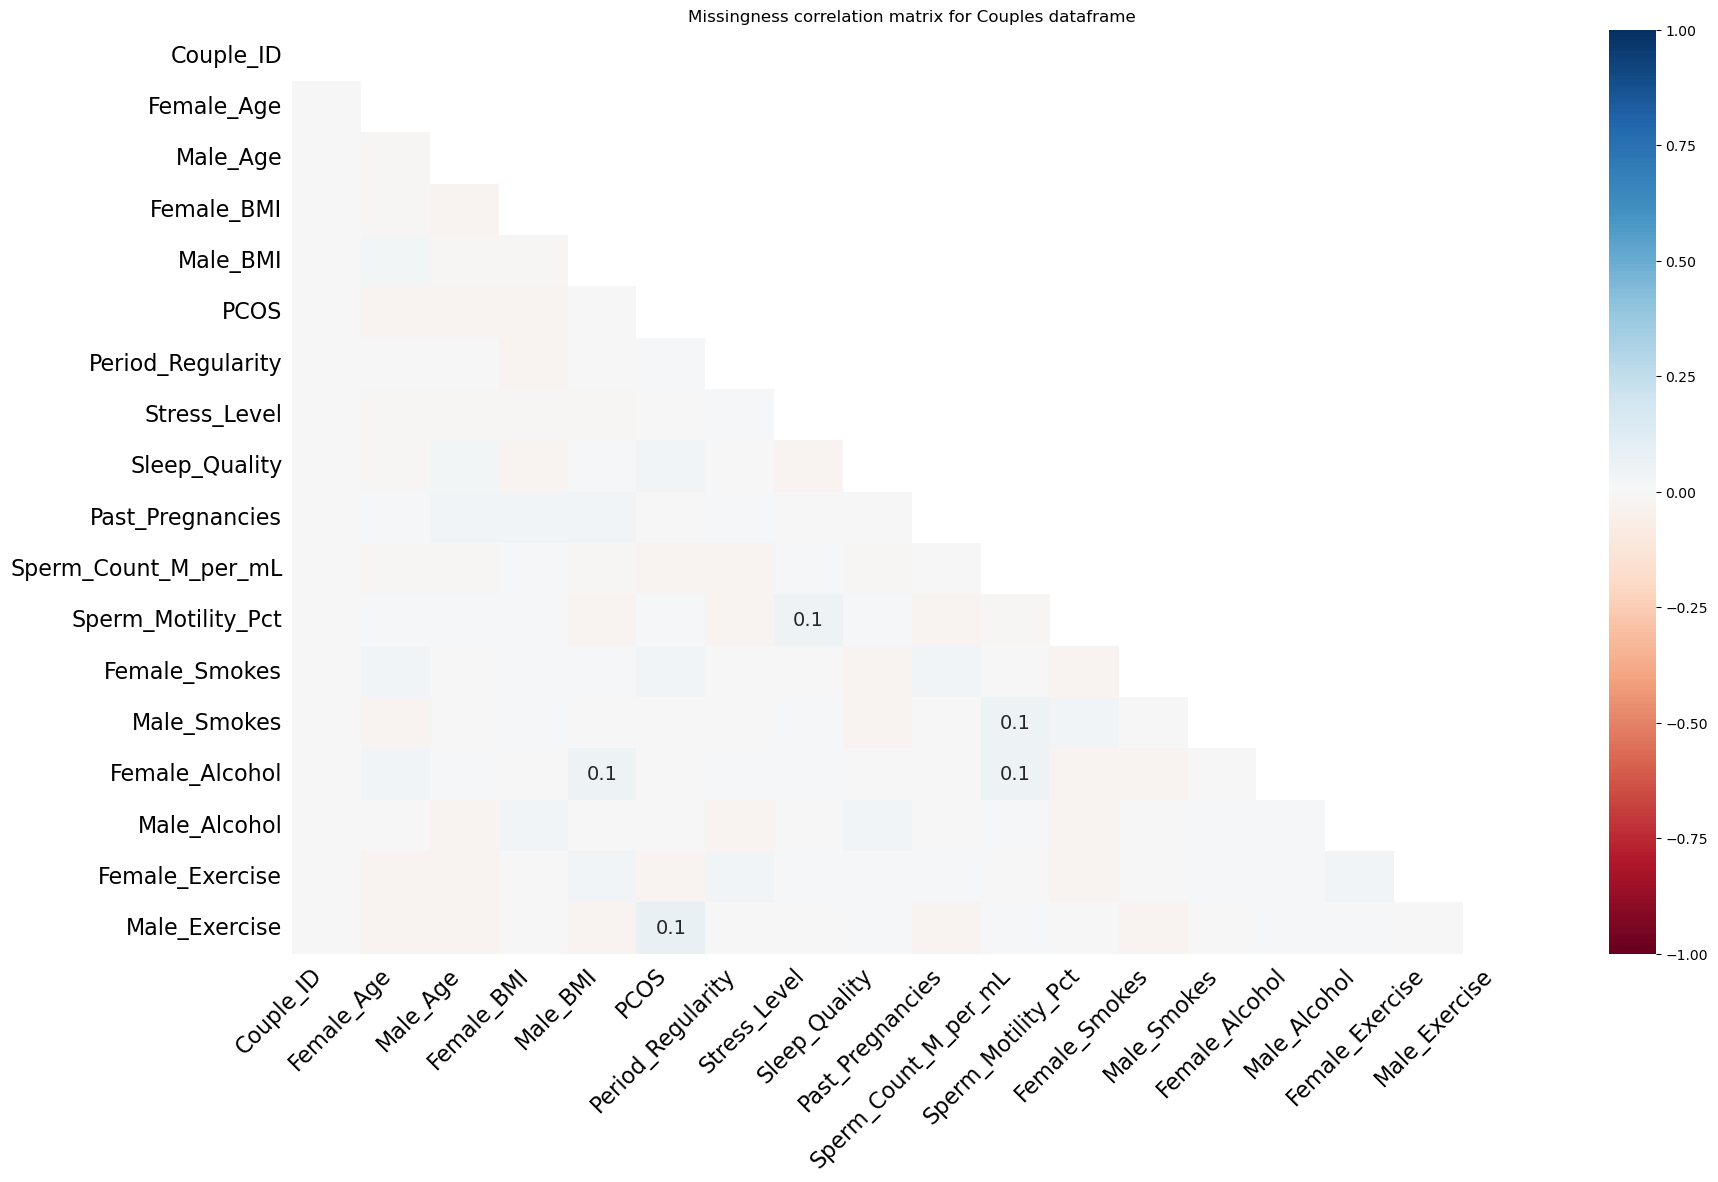

In [29]:
# check if missingness clusters together to determine which type of missing data is present in the data
msno.matrix(semen_df) 
msno.heatmap(semen_df) # shows correlation between which columns are missing together
plt.title("Missingness correlation matrix for Semen dataframe")

msno.matrix(couples_df)
msno.heatmap(couples_df) # shows correlation between which columns are missing together
plt.title("Missingness correlation matrix for Couples dataframe")

No significant correlation between the features were identified, so a random forest imputator was used to impute the NaN values to account for the skewness of the data

### Data encoding

In [30]:
# Use a copy after cleaning
analysis_couples = couples_df.copy()

# Separate outcome and ID
y = analysis_couples["Pregnancy_Success"]
ids = analysis_couples["Couple_ID"]

X = analysis_couples.drop(columns=["Couple_ID", "Pregnancy_Success"])

# define the categorical columns
couples_categorical_cols = [
    "PCOS", "Period_Regularity",
    "Female_Smokes", "Male_Smokes",
    "Female_Alcohol", "Male_Alcohol",
    "Female_Exercise", "Male_Exercise"
]

# Make categorical columns compatible with OrdinalEncoder
X_cat_input = X[couples_categorical_cols].copy()

# Convert pandas NA to numpy NaN
X_cat_input = X_cat_input.astype("object")
X_cat_input[X_cat_input.isna()] = np.nan

# encode categorical variables
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1,
    encoded_missing_value=np.nan
)

X_cat = pd.DataFrame(
    encoder.fit_transform(X_cat_input),
    columns=couples_categorical_cols,
    index=X.index
)

couples_numeric_cols = [col for col in X.columns if col not in couples_categorical_cols]

X_num = X[couples_numeric_cols].copy()
X_encoded = pd.concat([X_num, X_cat], axis=1)

# Generate one of several imputed datasets
imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(
        n_estimators=100,
        random_state=123,
        n_jobs=-1
    ),
    max_iter=20,
    sample_posterior=False,
    random_state=123
)

X_imp = pd.DataFrame(
    imputer.fit_transform(X_encoded),
    columns=X_encoded.columns,
    index=X.index
)

# keep numerical version for random forest
couples_X_for_rf = X_imp.copy()

# Decode categorical variables
X_cat_decoded = encoder.inverse_transform(
    X_imp[couples_categorical_cols].to_numpy().copy()
)

X_imp[couples_categorical_cols] = X_cat_decoded

completed_couples = pd.concat(
    [ids, X_imp, y],
    axis=1
)

c:\Users\fille\anaconda3\anaconda\envs\env\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [31]:
# Use a copy after cleaning
analysis_semen = semen_df.copy()

# Separate outcome and ID
y_semen = analysis_semen["Diagnosis"]
X_semen = analysis_semen.drop(columns=["Diagnosis"])

# define categorical columns
semen_categorical_cols = [
    "Season", "Childish diseases",
    "Accident or serious trauma",
    "Surgical intervention",
    "High fevers in the last year",
    "Frequency of alcohol consumption",
    "Smoking habit"
]

# encode categorical variables
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1,
    encoded_missing_value=np.nan
)

semen_X_cat = pd.DataFrame(
    encoder.fit_transform(X_semen[semen_categorical_cols]),
    columns=semen_categorical_cols,
    index=X_semen.index
)

# separate numerical columns
semen_numeric_cols = [col for col in X_semen.columns if col not in semen_categorical_cols]
semen_X_num = X_semen[semen_numeric_cols].copy()

# combine numerical and categorical columns
semen_X_encoded = pd.concat([semen_X_num, semen_X_cat], axis=1)

# impute missing values
imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=100, random_state=123, n_jobs=-1),
    max_iter=20,
    sample_posterior=False,
    random_state=123
)

semen_X_imp = pd.DataFrame(
    imputer.fit_transform(semen_X_encoded),
    columns=semen_X_encoded.columns,
    index=X_semen.index
)

# keep numerical version for random forest
semen_X_for_rf = semen_X_imp.copy()

# round before decoding — IterativeImputer produces continuous values, encoder expects integer codes
semen_X_imp[semen_categorical_cols] = semen_X_imp[semen_categorical_cols].round().astype(int)
semen_X_imp[semen_categorical_cols] = encoder.inverse_transform(semen_X_imp[semen_categorical_cols])
completed_semen = pd.concat([semen_X_imp, y_semen], axis=1)

c:\Users\fille\anaconda3\anaconda\envs\env\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [32]:
print(semen_X_for_rf.head)
print(couples_X_for_rf.head)

<bound method NDFrame.head of       Age  Number of hours spent sitting per day  Season  Childish diseases  \
0   30.00                                   16.0    1.00                0.0   
1   35.00                                    6.0    1.00                1.0   
2   27.00                                    9.0    1.00                1.0   
3   32.00                                    7.0    1.00                0.0   
4   30.00                                    9.0    1.92                1.0   
..    ...                                    ...     ...                ...   
95  30.00                                    9.0    3.00                1.0   
96  29.00                                    9.0    3.00                1.0   
97  30.34                                    6.0    3.00                1.0   
98  30.00                                    3.0    3.00                1.0   
99  30.00                                    3.0    3.00                0.0   

    Accident or serio

In [33]:
print(completed_semen.head)
print(completed_couples.head)

<bound method NDFrame.head of       Age  Number of hours spent sitting per day  Season Childish diseases  \
0   30.00                                   16.0  spring                no   
1   35.00                                    6.0  spring               yes   
2   27.00                                    9.0  spring               yes   
3   32.00                                    7.0  spring                no   
4   30.00                                    9.0  summer               yes   
..    ...                                    ...     ...               ...   
95  30.00                                    9.0  winter               yes   
96  29.00                                    9.0  winter               yes   
97  30.34                                    6.0  winter               yes   
98  30.00                                    3.0  winter               yes   
99  30.00                                    3.0  winter                no   

   Accident or serious trauma Sur

In [34]:
# replace the binary values with 0 and 1 for easier analysis
binary_mapping = {"yes": 1, "no": 0, "altered": 1, "normal":0, "irregular":1, "regular": 0}
semen_df_completed = completed_semen.replace(binary_mapping)
couples_df_completed = completed_couples.replace(binary_mapping)

In [ ]:
# save encoded df as CSV
couples_df_completed = couples_df_completed.to_csv("couples_df_completed.csv", index = False)
semen_df_completed = semen_df_completed.to_csv("semen_df_completed.csv", index = False)

AttributeError: 'NoneType' object has no attribute 'head'

In [55]:
# harmonize the features in both data sets
alc_map = {"none": 0, "low": 1, "moderate": 2, "high": 3}
yn_map = {"yes": 1, "no": 0, 1: 1, 0: 0, "1": 1, "0": 0}

shared_semen = pd.DataFrame({
    "age": completed_semen["Age"],
    "smoker": completed_semen["Smoking habit"].map(yn_map),
    "alcohol": completed_semen["Frequency of alcohol consumption"].map(alc_map),
})
shared_couples = pd.DataFrame({
    "age": completed_couples["Male_Age"],
    "smoker": completed_couples["Male_Smokes"].map(yn_map),
    "alcohol": completed_couples["Male_Alcohol"].map(alc_map),
})

# these should both be 0, otherwise a category didn't match the map
print(shared_semen.isna().sum(), shared_couples.isna().sum())

# map the outcome columns
y_semen_bin = completed_semen["Diagnosis"].map({"altered": 1, "normal": 0, 1: 1, 0: 0})
y_couples_bin = completed_couples["Pregnancy_Success"]

y_couples_bin.head()
y_semen_bin.head()

age        0
smoker     0
alcohol    0
dtype: int64 age        0
smoker     0
alcohol    0
dtype: int64


0    0
1    1
2    0
3    0
4    1
Name: Diagnosis, dtype: int64

## investigation

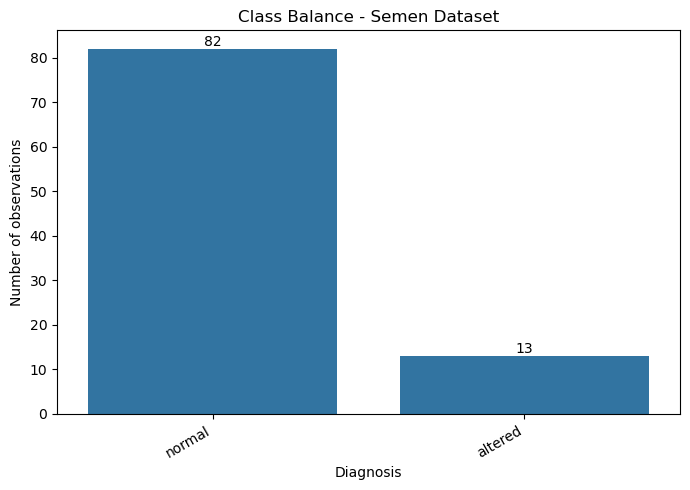

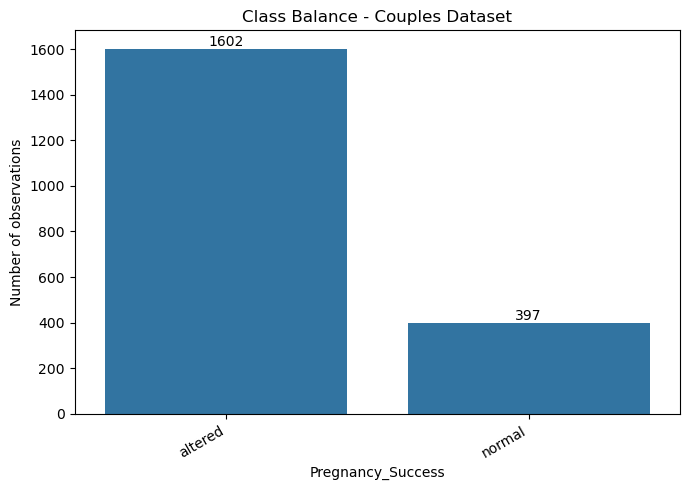

In [37]:
def plot_class_balance(df, target_col, title):
    counts = df[target_col].fillna("Missing").astype(str).value_counts()

    plt.figure(figsize=(7, 5))
    ax = sns.barplot(
        x=counts.index,
        y=counts.values
    )

    ax.bar_label(ax.containers[0], fmt="%d")
    plt.title(title)
    plt.xlabel(target_col)
    plt.ylabel("Number of observations")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()



plot_class_balance(
    completed_semen,
    target_col="Diagnosis",
    title="Class Balance - Semen Dataset"
)

plot_class_balance(
    completed_couples,
    target_col="Pregnancy_Success",
    title="Class Balance - Couples Dataset"
)

### KDE plot

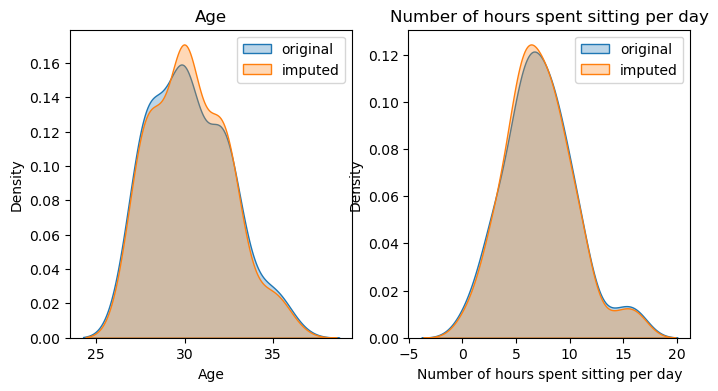

In [38]:
# verification that imputation did not introduce noise
fig, axes = plt.subplots(1, len(semen_numeric_cols), figsize=(4*len(semen_numeric_cols), 4))
for ax, col in zip(axes, semen_numeric_cols):
    sns.kdeplot(semen_df[col].dropna(), ax=ax, label="original", fill=True, alpha=0.3)
    sns.kdeplot(completed_semen[col], ax=ax, label="imputed", fill=True, alpha=0.3)
    ax.set_title(col)
    ax.legend()

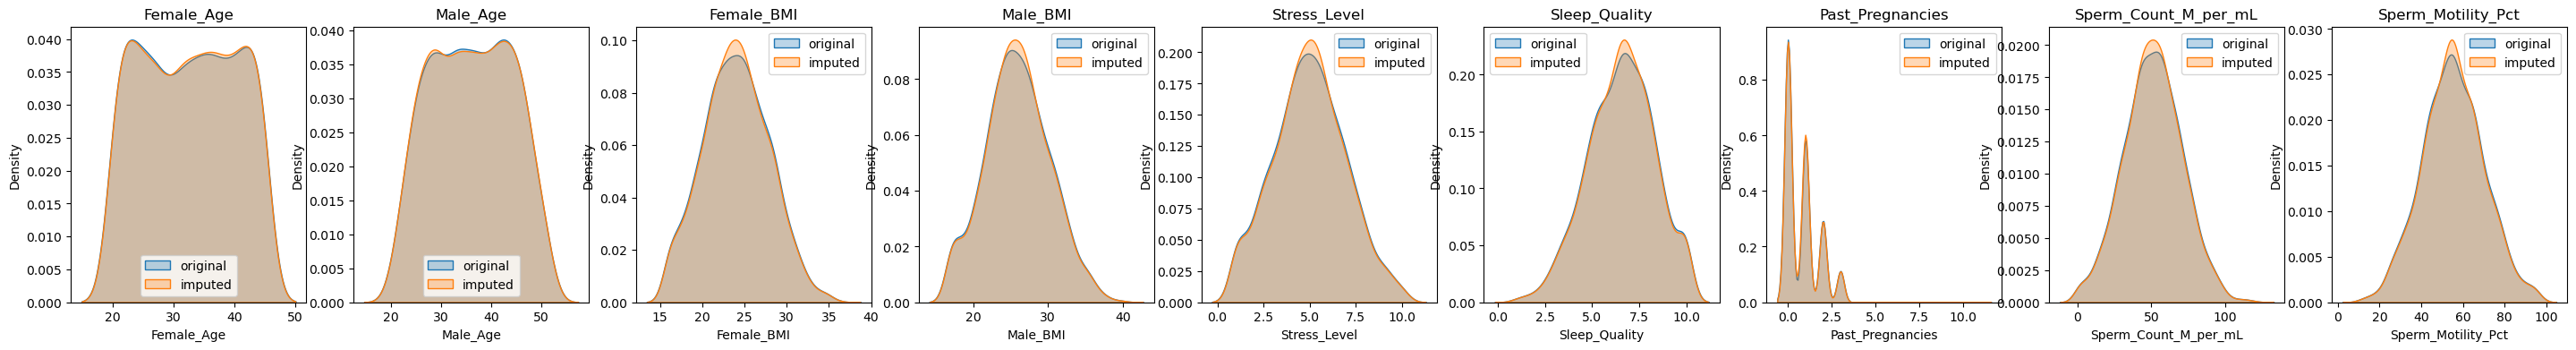

In [39]:
fig, axes = plt.subplots(1, len(couples_numeric_cols), figsize=(4*len(couples_numeric_cols), 4))
for ax, col in zip(axes, couples_numeric_cols):
    sns.kdeplot(couples_df[col].dropna(), ax=ax, label="original", fill=True, alpha=0.3)
    sns.kdeplot(completed_couples[col], ax=ax, label="imputed", fill=True, alpha=0.3)
    ax.set_title(col)
    ax.legend()

# URF plot

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50


Text(0.5, 1.0, 'URF PCA score plot - Semen Dataset')

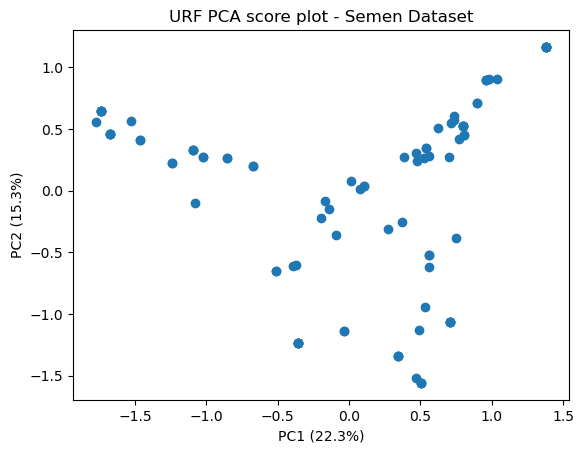

In [ ]:

# set color code
category_color = {"0" : "#3357FF", 
                  "1" : "#ff0000"}

# plot URF for the male-only dataset
result = script_urf(
    nr_iteration=50,
    real_data=completed_semen[semen_numeric_cols],  # numeric matrix, samples in rows
    color=category_color,
    nr_trees=1500,
    nr_samples=5
)

plt.scatter(result["scores"][:, 0], result["scores"][:, 1])
plt.xlabel(f"PC1 ({result['explained_variance_ratio'][0]:.1f}%)")
plt.ylabel(f"PC2 ({result['explained_variance_ratio'][1]:.1f}%)")
plt.title("URF PCA score plot - Semen Dataset")

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50


Text(0.5, 1.0, 'URF PCA score plot - Couples Dataset')

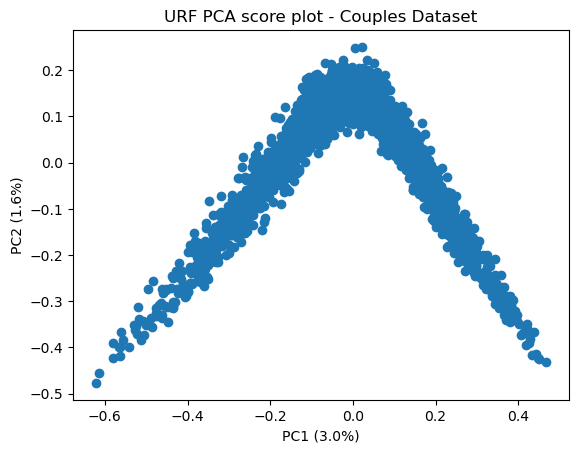

In [ ]:
# plot URF for the couples dataset
result = script_urf(
    nr_iteration=50,
    real_data=completed_couples[couples_numeric_cols],  # numeric matrix, samples in rows
    color=category_color,
    nr_trees=1500,
    nr_samples=5
)

plt.scatter(result["scores"][:, 0], result["scores"][:, 1])
plt.xlabel(f"PC1 ({result['explained_variance_ratio'][0]:.1f}%)")
plt.ylabel(f"PC2 ({result['explained_variance_ratio'][1]:.1f}%)")
plt.title("URF PCA score plot - Couples Dataset")

# feature importance

In [47]:
# ensure everythig is either an object or a string
print(couples_X_for_rf.dtypes[couples_X_for_rf.dtypes.isin(["object", "string", "str"])])

# define columns that would lead to leakage
leaky = {"Couple_ID", "Pregnancy_Success", "Sperm_Count_M_per_mL", "Sperm_Motility_Pct"}
print(leaky & set(couples_X_for_rf.columns))   # should be an empty set

# check that the changes were succesful 
print(len(couples_X_for_rf), len(y_couples_bin))
print((couples_X_for_rf.index == y_couples_bin.index).all())

Series([], dtype: object)
{'Sperm_Count_M_per_mL', 'Sperm_Motility_Pct'}
1999 1999
True


In [48]:
# define function for feature importance
def rf_importance(X, y, seed=132): # set seed for reproducibility
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)
    rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced", random_state=seed, n_jobs=-1)
    rf.fit(X_train, y_train)
    perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=seed)
    return pd.Series(perm.importances_mean, index=X.columns).sort_values()

In [49]:
# full feature sets 
X_couples_full = couples_X_for_rf.drop(columns=["Sperm_Count_M_per_mL", "Sperm_Motility_Pct"])
# Exclude any variables used to construct the target
X_semen_full = semen_X_for_rf.drop(columns=["Sperm_Count_M_per_mL", "Sperm_Motility_Pct"], errors="ignore")

# Calculate feature importance
imp_semen = rf_importance(X_semen_full, y_semen_bin)
imp_couples = rf_importance(X_couples_full, y_couples_bin)
imp_shared_couples = rf_importance(shared_couples, y_couples_bin)
imp_shared_semen = rf_importance(shared_semen, y_semen_bin)  # n≈96, treat as very rough

In [50]:
# set up function to define feature importance
def plot_feature_importance(importance, title, top_n=15):
    # Select the top features by importance
    top_features = importance.sort_values(ascending=False).head(top_n)

    # Sort for a horizontal bar chart
    top_features = top_features.sort_values(ascending=True)

    # Create the figure
    fig, ax = plt.subplots(figsize=(9, 6))

    top_features.plot(kind="barh", ax=ax)

    # Reference line at zero
    ax.axvline(0, linewidth=1)

    ax.set_title(title)
    ax.set_xlabel("Mean decrease in ROC-AUC after permutation")
    ax.set_ylabel("Feature")

    plt.tight_layout()
    plt.show()

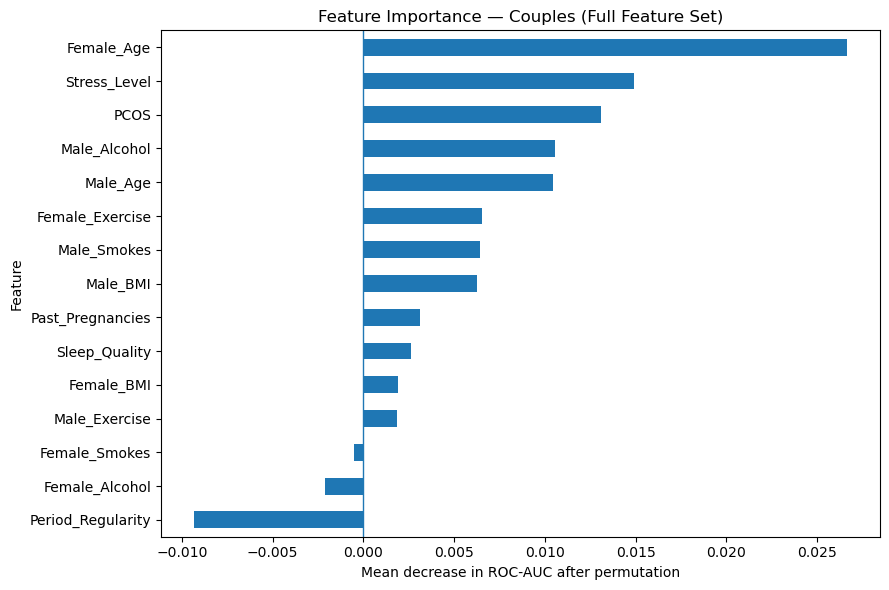

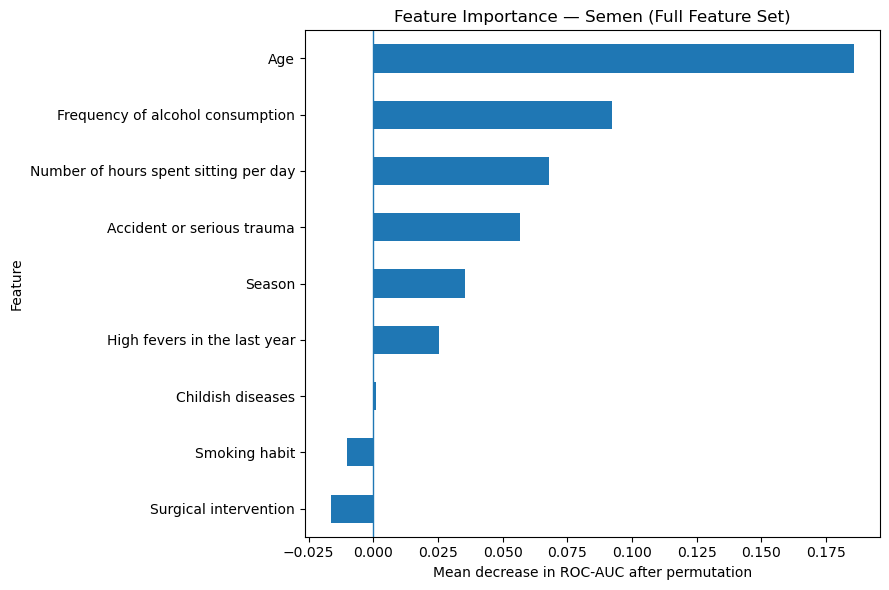

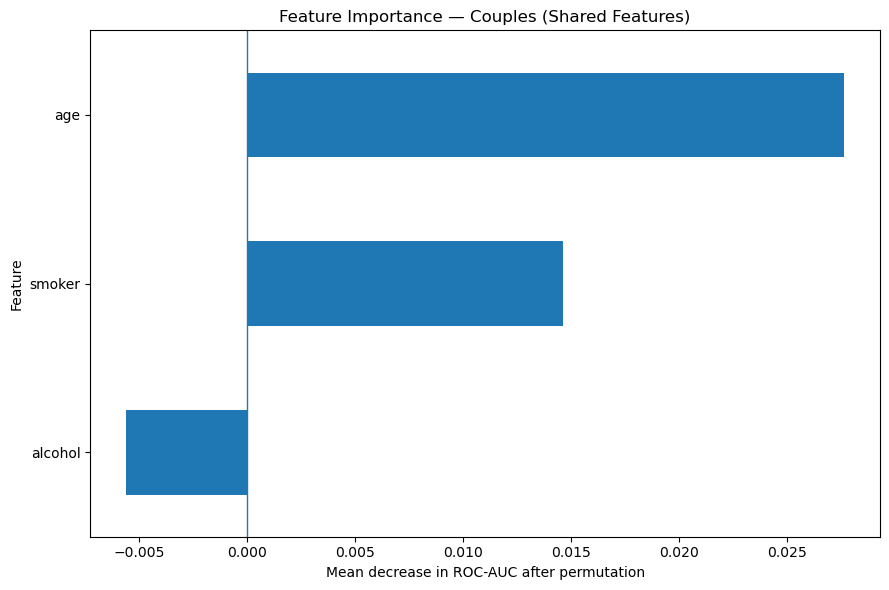

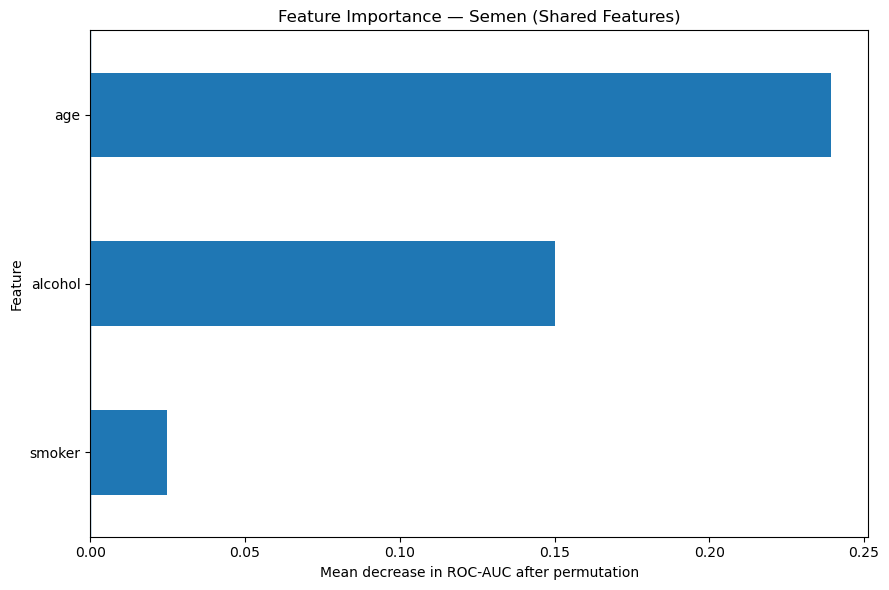

In [51]:
# 1. Couples: full feature set
plot_feature_importance(
    imp_couples,
    "Feature Importance — Couples (Full Feature Set)"
)
# 2. Semen: full feature set
plot_feature_importance(
    imp_semen,
    "Feature Importance — Semen (Full Feature Set)"
)

# 3. Couples: shared features
plot_feature_importance(
    imp_shared_couples,
    "Feature Importance — Couples (Shared Features)"
)

# 4. Semen: shared features
plot_feature_importance(
    imp_shared_semen,
    "Feature Importance — Semen (Shared Features)"
)

# investigate predictability of artificial data set

In [90]:
# define function to investigate predictability of artificial dataset on real world dataset
def transfer_test(X_train, y_train, X_test, y_test, label):
    rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced", random_state=123, n_jobs=-1)

    rf.fit(X_train, y_train)
    p = rf.predict_proba(X_test)[:,1]
    pred = (p>=0.5).astype(int)

    # bootstrap CI for AUC, 
    rng = np.random.default_rng(0)
    y_arr = np.asarray(y_test)
    aucs = []
    for _ in range (2000):
        idx = rng.integers(0, len(y_arr), len(y_arr))
        if len(np.unique(y_arr[idx]))<2:
            continue
        aucs.append(roc_auc_score(y_arr[idx], p[idx]))
    lo, hi = np.percentile(aucs, [2.5, 97.5])

    print(f"{label}: AUC={roc_auc_score(y_arr, p):.2f} (95% CI {lo:.2f}-{hi:.2f}),"
            f"balanced acc={balanced_accuracy_score(y_arr, pred):.2f},"
            f"recall(Altered)={recall_score(y_arr, pred):.2f}")

In [52]:
def transfer_test(X_train, y_train, X_test, y_test, label):
    rf = RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=123,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    # Predict the probability of being altered
    p = rf.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)

    y_arr = np.asarray(y_test)

    # Bootstrap 95% confidence interval for AUC
    rng = np.random.default_rng(0)
    aucs = []

    for _ in range(2000):
        idx = rng.integers(0, len(y_arr), len(y_arr))

        # AUC requires both classes to be present
        if len(np.unique(y_arr[idx])) < 2:
            continue

        aucs.append(roc_auc_score(y_arr[idx], p[idx]))

    lo, hi = np.percentile(aucs, [2.5, 97.5])

    auc = roc_auc_score(y_arr, p)
    bal_acc = balanced_accuracy_score(y_arr, pred)
    altered_recall = recall_score(
        y_arr, pred, pos_label=1, zero_division=0
    )

    print(
        f"{label}: AUC={auc:.2f} (95% CI {lo:.2f}–{hi:.2f}), "
        f"balanced accuracy={bal_acc:.2f}, "
        f"altered recall={altered_recall:.2f}"
    )

    return {
        "label": label,
        "auc": auc,
        "ci_low": lo,
        "ci_high": hi,
        "balanced_accuracy": bal_acc,
        "altered_recall": altered_recall,
        "y_true": y_arr,
        "probabilities": p,
        "predictions": pred
    }

In [57]:
# Couples model predicting the semen dataset
result_c2s = transfer_test(
    shared_couples, y_couples_bin,
    shared_semen, y_semen_bin,
    "Couples → Semen"
)

# Semen model predicting the couples dataset
result_s2c = transfer_test(
    shared_semen, y_semen_bin,
    shared_couples, y_couples_bin,
    "Semen → Couples"
)

Couples → Semen: AUC=0.38 (95% CI 0.23–0.53), balanced accuracy=0.43, altered recall=0.46
Semen → Couples: AUC=0.58 (95% CI 0.56–0.62), balanced accuracy=0.53, altered recall=0.16


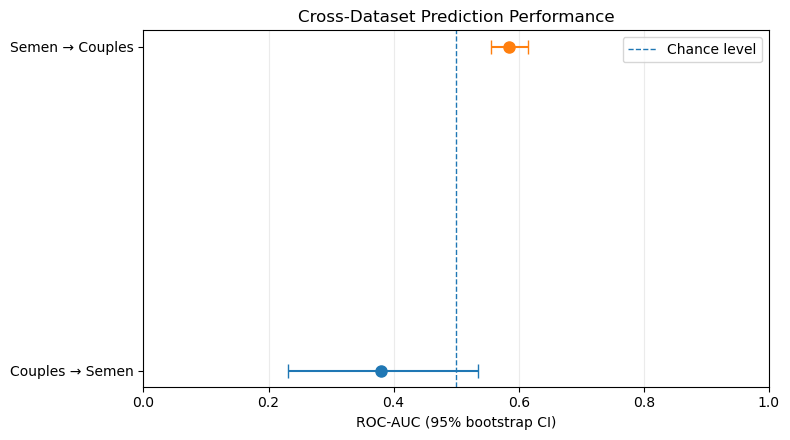

In [58]:
results = [result_c2s, result_s2c]

fig, ax = plt.subplots(figsize=(8, 4.5))

for i, r in enumerate(results):
    lower_error = r["auc"] - r["ci_low"]
    upper_error = r["ci_high"] - r["auc"]

    ax.errorbar(
        r["auc"], i,
        xerr=[[lower_error], [upper_error]],
        fmt="o",
        capsize=5,
        markersize=8
    )

ax.axvline(0.5, linestyle="--", linewidth=1, label="Chance level")
ax.set_yticks(range(len(results)))
ax.set_yticklabels([r["label"] for r in results])
ax.set_xlim(0, 1)
ax.set_xlabel("ROC-AUC (95% bootstrap CI)")
ax.set_title("Cross-Dataset Prediction Performance")
ax.legend()
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

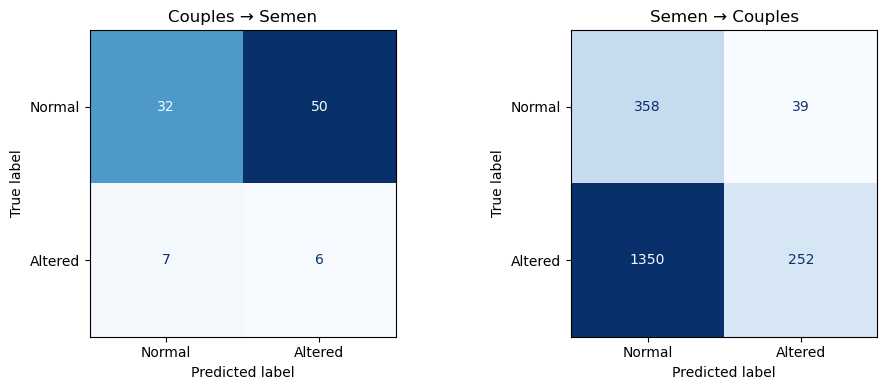

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, result in zip(axes, results):
    cm = confusion_matrix(
        result["y_true"],
        result["predictions"],
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Altered"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(result["label"])

plt.tight_layout()
plt.show()

In [60]:
rf_loo = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=123,
    n_jobs=-1
)

p_loo = cross_val_predict(
    rf_loo,
    shared_semen,
    y_semen_bin,
    cv=LeaveOneOut(),
    method="predict_proba",
    n_jobs=-1
)[:, 1]

y_loo = np.asarray(y_semen_bin)

print(
    "Semen LOOCV AUC:",
    round(roc_auc_score(y_loo, p_loo), 3)
)

Semen LOOCV AUC: 0.56


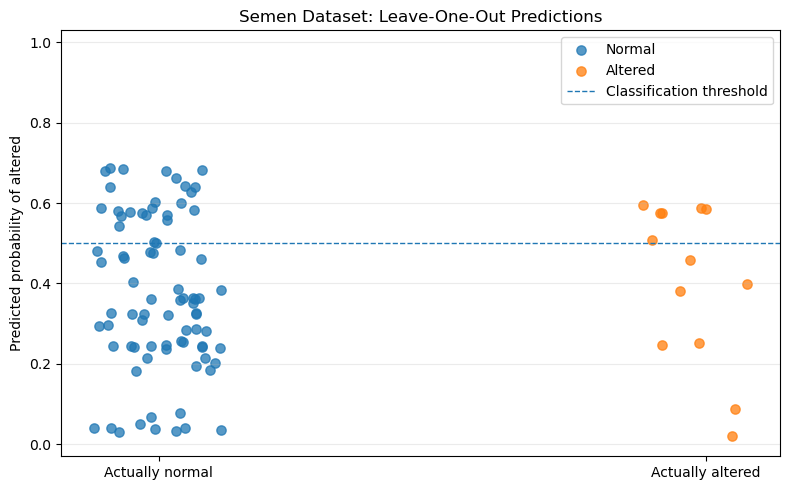

In [61]:
fig, ax = plt.subplots(figsize=(8, 5))

rng = np.random.default_rng(42)

for label, name in [(0, "Normal"), (1, "Altered")]:
    mask = y_loo == label

    # Small horizontal jitter helps separate overlapping points
    x = label + rng.uniform(-0.12, 0.12, mask.sum())

    ax.scatter(
        x,
        p_loo[mask],
        alpha=0.75,
        s=45,
        label=name
    )

ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1,
    label="Classification threshold"
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Actually normal", "Actually altered"])
ax.set_ylabel("Predicted probability of altered")
ax.set_title("Semen Dataset: Leave-One-Out Predictions")
ax.set_ylim(-0.03, 1.03)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()